<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/08_Phishing_Detection/QSVM_EmailPhishing_Hridi2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Batch-wise QSVM ensemble for email phishing detection: Hridi et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Mehnaj Hridi, Zaima Ahmed, Ahnaf Shahrier Tasin and Fernaz Narin Nur, "Batch-Wise Ensemble Evaluation of Classical SVM and
> Quantum SVM for Email Phishing Detection", *2026 IEEE 2nd International Conference on Quantum Photonics, Artificial
> Intelligence, and Networking (QPAIN)*, Chittagong, Bangladesh, 2026. DOI 10.1109/QPAIN69676.2026.11546403

The paper publishes no code. Everything below is written from its six-page description, with the stack it names: Qiskit
(`ZZFeatureMap`, a fidelity quantum kernel, `QSVC`) for the quantum part and scikit-learn for the classical SVM, mutual
information and the metrics.

**What the notebook does.** It downloads the email corpus the paper uses (CEAS-08) and a public web-page phishing data set,
builds a "hybrid" email + web-page table in the way the paper describes, engineers features of the six families the paper lists,
fits every transform on the training split only, keeps the six features with the highest mutual information (one per qubit),
rescales them to rotation angles in $[0,\pi]$, and then trains - on fixed-size batches of the training set, one fresh model per
batch - a classical RBF-kernel SVM and a quantum-kernel SVM (6-qubit `ZZFeatureMap`, `reps = 1`, linear entanglement,
fidelity kernel). Each family of batch models predicts the same held-out test set and the final label is the **majority vote
over batches**. The notebook draws the executed circuit, re-computes the paper's Table I and Figures 3-6, adds a few
checks the paper lists as future work (McNemar test, several seeds, tuned bandwidths), and ends with a per-claim verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned versions of Qiskit; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account
and no Hugging Face token are needed (the data are public).

**Runtime.** `FAST_MODE = True` (2,400 rows, batches of 150, 5 batches, one seed) took 2.6 minutes on the validation machine, a shared
laptop CPU; expect 3-6 minutes on a Colab CPU. `FAST_MODE = False` (the paper's 8,000 rows, batches of 500, all 13 batches,
three seeds, bandwidth search) took 5 to 7 minutes on the same machine, of which the 13 QSVM batches take about 1.2 minutes; expect
10-15 minutes on Colab. The committed notebook contains the outputs of the full run. The paper needed about 4 hours for the 13 QSVM
batches because it simulated one circuit per kernel entry, whereas this notebook simulates one statevector per sample (the kernel
values are identical, see Section 5).

**What you get at the end.** Accuracy, precision, recall, F1, ROC-AUC, confusion matrices and false-negative counts of the SVM
and QSVM ensembles, batch-wise accuracy curves, a table that puts the paper's numbers next to ours with a verdict per claim,
and a critical reading of the paper. **Important:** the paper's web-page data set (Singh, *Data in Brief* 2020) is only
available behind a Cloudflare challenge on Mendeley or Kaggle login, so a public web-page phishing data set is substituted;
the numbers therefore test the *method*, not the paper's exact table.

## The paper in one page

**Problem.** Decide whether an email (plus the web page its link points to) is phishing or legitimate. The paper's claim is that
a quantum-kernel SVM ensemble misses far fewer phishing cases (false negatives) than a classical SVM ensemble, at a much
higher computational cost.

**Data.** Email side: the `CEAS_08.csv` subset of the "Phishing Email Dataset" (Alam 2024; 39,154 emails with sender, subject,
body, label, a has-URL flag). Web side: the "Malicious and Benign Webpages Dataset" (Singh 2020; URL, IP, geo-location, JS
length, obfuscated-JS length, TLD, WHOIS, HTTPS, page content, label). The two are merged and cut to 8,000 rows with equal class
proportions; email URL length, number of links, the email label and unnamed web columns are removed.

**Features.** "38 features: 14 original and 24 engineered": URL structure (special-character counts, sub-domains, digits in the
domain, suspicious TLD, IP-based URL, JavaScript obfuscation ratio), Shannon entropy of URL / domain / content, a composite
domain-trust score (domain age, HTTPS, WHOIS completeness, TLD reputation), email-vs-URL consistency (sender-domain match and
similarity), web-content indicators (forms, inputs, script tags, keywords) and semantic / brand consistency (TF-IDF cosine
similarity, brand scores).

**Preprocessing.** Drop rows with a missing sender domain (8,000 -> 7,822); binary `domain_age_missing` indicator and zero
imputation; frequency encoding of the sender domain and geo-location; TLD mapped to a binary trust score; WHOIS and HTTPS as
binary; 80 : 20 stratified split (6,257 / 1,565); Min-Max scaling to [0, 1]; mutual-information ranking on the training set,
top 6 kept: `web_js_len`, `js_obfuscation_ratio`, `web_js_obf_len`, `content_num_scripts`, `content_entropy`,
`domain_trust_score`; then scaling to $[0,\pi]$.

**Models.** Classical: RBF-kernel SVM with balanced class weights. Quantum: `ZZFeatureMap` (6 qubits, `reps = 1`, linear
entanglement), fidelity kernel $K(x_i,x_j)=|\langle\phi(x_i)|\phi(x_j)\rangle|^2$, `QSVC`, simulated with Qiskit Aer. The
training set is cut into fixed-size batches (500 samples per batch: "500 samples -> 250,000 kernel evaluations", 13 batches),
a fresh SVM and QSVM is trained on each batch, every batch model predicts the shared test set, and the final label is the
majority vote.

**Claims (Table I, Sections V.B-V.D).**

| Metric | Classical SVM | QSVM |
|---|---|---|
| Accuracy | 97.70 % | 98.79 % |
| Recall (phishing) | 96.2 % | 99.2 % |
| F1 | 97.7 % | 98.8 % |
| ROC-AUC | 0.977 | 0.988 |
| False negatives | 29 | 6 (-79 %) |

Batch-wise accuracy over 13 batches: SVM 95.5 - 98.7 % (sigma about 0.009), QSVM 96.0 - 98.3 % (sigma about 0.007). Training time
per batch: SVM 0.12 - 0.28 s, QSVM 340 - 1,688 s (about 5,500 times slower; 13 batches take about 4 hours). Implementation: Python
3.12, Qiskit 1.4, Qiskit Aer, scikit-learn 1.8, a 20 GB Windows laptop.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Email data | CEAS_08.csv (Alam 2024, Kaggle) | the same file from the Zenodo mirror of the curated phishing-email corpora (Champa et al.), 39,154 emails |
| Web-page data | Singh 2020, "Malicious and Benign Webpages" (JS length, obfuscation, content entropy, ...) | **substituted**: the public "Web Page Phishing Detection" data set (Hannousse and Yahiouche 2021; 11,430 URLs, 50 : 50, 87 URL / HTML / domain features) from a Hugging Face mirror. Singh's data are behind a Cloudflare challenge (Mendeley) or a Kaggle login and cannot be downloaded in a notebook. It has no JavaScript length / obfuscation / page-content columns, so the paper's six selected features cannot exist here (CHOICE) |
| How emails and web pages are joined | not stated ("combined with"); the two data sets share no key | **row-wise pairing after independent shuffling** of the 8,000 web pages with 8,000 random emails (`PAIRING = "random"`); the final label is the web label ("email label" is dropped, as in the paper). `PAIRING = "same_label"` pairs emails of the same class instead (CHOICE, see exercise 5) |
| Rows | 8,000, then 7,822 after dropping missing sender domains | `N_TOTAL` = 8,000 balanced web rows; emails without a parseable sender domain are removed *before* drawing, so no row is lost afterwards |
| Features | 14 original + 24 engineered = 38 (+ missingness indicator = 39) | about the same split: original = closest analogues of Singh's attributes plus 3 email attributes; engineered = structure / entropy / trust / consistency / keyword / brand features computed here (the exact list of the paper is not given). The real count is printed |
| Domain trust score | "domain age, HTTPS, WHOIS completeness, TLD reputation", weights not given | 0.35 age >= 1 year + 0.25 HTTPS + 0.25 WHOIS record present + 0.15 trusted TLD (CHOICE) |
| Encoding | frequency encoding of sender domain; TLD -> binary trust; WHOIS, HTTPS binary | same (fitted on the training split only) |
| Split | 80 : 20 stratified | same, `random_state = SEED` |
| Scaling | Min-Max to [0, 1], then to [0, pi] for the circuit | same, fitted on training split only, test angles clipped to [0, pi] |
| Feature selection | mutual information on the training set, top 6 | `mutual_info_classif(random_state = SEED)` on the training split, top 6 = `N_QUBITS` |
| Feature map | `ZZFeatureMap`, 6 qubits, `reps = 1`, linear entanglement | `zz_feature_map(6, reps=1, entanglement="linear")` (Qiskit 2.x function form) |
| Kernel | `FidelityQuantumKernel` on Aer (one circuit per kernel entry) | Qiskit's `FidelityStatevectorKernel` (exact fidelity from statevectors) with its Gram matrix computed by one matrix product (subclass in Section 5); equal to the paper's circuit kernel and to the original class (asserted in the circuit section and in Section 5) |
| Classical SVM | RBF kernel, balanced class weights, `C`, `gamma` not given | `SVC(kernel="rbf", class_weight="balanced")` with scikit-learn defaults `C=1`, `gamma="scale"`; a tuned version is added as an extra |
| QSVM `C` | not given | `QSVC` default `C = 1` |
| Batch size / number | 500 samples / 13 batches (6,257 / 500 = 12.5) | `BATCH_SIZE = 500`; consecutive slices of the shuffled training set, last one partial; 13 batches |
| Vote | majority over "valid batches" | majority vote, a tie (only possible with an even number of batches) goes to *phishing* |
| ROC-AUC of an ensemble | not explained | AUC of the fraction of batch models that vote "phishing" (CHOICE) |
| Bandwidth | none (angles in [0, pi]) | paper setting (bandwidth 1) is the headline; bandwidths 0.1 / 0.25 / 0.5 / 1 are chosen on a validation split of the training data as an extra |
| Seeds | one split, seed not given | `SEED = 42` for the headline; two more seeds in the full run |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub
    print("Qiskit installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit and qiskit-machine-learning already present; skipping pip install.")

qiskit and qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: 2,400 rows, batches of 150, 5 batches, one seed (a few minutes). False: the paper's 8,000 rows / 500 per batch / 13 batches.
SEED      = 42             # CHOICE: the paper gives no seed
N_QUBITS  = 6              # paper: 6 selected features = 6 qubits
FM_REPS   = 1              # paper: ZZFeatureMap repeated once
ENTANGLEMENT = "linear"    # paper: linear entanglement
TEST_SIZE = 0.20           # paper: 80 : 20 stratified split
PAIRING   = "random"       # "random": pair emails with web pages independently of the class (CHOICE, see table above); "same_label": pair within the class
SVM_C, SVM_GAMMA = 1.0, "scale"      # CHOICE: scikit-learn defaults, the paper gives neither
LOG_SKEWED = False        # CHOICE: True applies log1p to heavy-tailed non-negative columns (skew > 5 on the training split) before Min-Max; the paper only says Min-Max
TIE_GOES_TO = 1            # CHOICE: an even number of batches could tie; a tie is read as phishing (class 1)

if FAST_MODE:
    N_TOTAL      = 2400    # rows of the hybrid table (paper: 8,000)
    BATCH_SIZE   = 150     # paper: 500
    MAX_BATCHES  = 5       # None = use every batch
    EXTRA_SEEDS  = []      # additional full pipelines for mean +- std
    BW_GRID      = [0.5, 1.0]            # CHOICE: angle-bandwidth candidates for the extra "tuned" QSVM
    N_FIG_ROWS   = 1500    # rows drawn in the scatter plots
else:
    N_TOTAL      = 8000
    BATCH_SIZE   = 500
    MAX_BATCHES  = None
    EXTRA_SEEDS  = [43, 44]
    BW_GRID      = [0.1, 0.25, 0.5, 1.0]
    N_FIG_ROWS   = 3000

GAMMA_GRID = ["scale", 0.3, 1.0, 3.0, 10.0]   # CHOICE: candidates for the tuned classical SVM (extra)
C_GRID     = [1.0, 10.0]
RUN_TUNED_EXTRA = True     # tuned SVM / tuned-bandwidth QSVM ensembles for the headline seed
IBM_TOKEN  = ""            # optional; this notebook never needs it (no hardware cell)

DATA_DIR = "data"
WEB_LOCAL_CSV  = ""        # optional: path of your own copy of dataset_phishing.csv
CEAS_LOCAL_CSV = ""        # optional: path of your own copy of CEAS_08.csv

In [3]:
import os, re, time, math, warnings, difflib
from urllib.parse import urlparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, scipy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)
from scipy.stats import binomtest

import qiskit, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

# Hugging Face token: the web-page data set is public, so none is needed. If you have one, it is only read from the
# environment or from Colab Secrets (Settings > Secrets > HF_TOKEN) and never written anywhere. A *gated* data set would need your own token.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("FAST_MODE =", FAST_MODE, "| rows:", N_TOTAL, "| batch size:", BATCH_SIZE, "| qubits:", N_QUBITS, "| pairing:", PAIRING)
T_NOTEBOOK_START = time.time()

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1
FAST_MODE = False | rows: 8000 | batch size: 500 | qubits: 6 | pairing: random


## 1. The two data sources

**Email side - CEAS-08.** The paper takes "only the `CEAS_08.csv` subset" of the Phishing Email Dataset. That file is part of
the curated corpora published on Zenodo (record 8339691): 39,154 emails from the CEAS 2008 spam challenge with the columns
`sender, receiver, date, subject, body, label, urls` (`label` 1 = phishing / spam, 0 = legitimate; `urls` = the email contains a link).

**Web side.** The paper uses Singh's "Malicious and Benign Webpages" data (Mendeley Data, DOI 10.17632/gdx3pkwp47.2): about 1.2
million pages with URL, IP, geo-location, JavaScript length and obfuscated length, TLD, WHOIS, HTTPS flag, raw content and a Google
Safe Browsing label. Mendeley answers programmatic requests with a Cloudflare challenge and Kaggle needs a login, and no mirror
of the file exists on Hugging Face or GitHub, so it cannot be fetched inside a notebook. We substitute the closest public data
set: **Web Page Phishing Detection** (Hannousse and Yahiouche, 2021; 11,430 URLs, exactly 50 % phishing, 87 pre-computed URL,
HTML-content and domain features including `domain_age`, `google_index`, `page_rank`, `web_traffic`). It plays the same role (a
balanced table of web-page attributes with a phishing / legitimate label that carries all the signal in the paper's final
model) but has no JavaScript-length or page-entropy columns. Both files are cached in `DATA_DIR`.

In [4]:
import requests
from huggingface_hub import hf_hub_download

def get_web_csv():
    if WEB_LOCAL_CSV: return WEB_LOCAL_CSV
    try:
        return hf_hub_download("yonatane22-bh/Web_page_Phishing", "dataset_phishing.csv", repo_type="dataset",
                               local_dir=DATA_DIR, token=HF_TOKEN)      # public mirror of the Hannousse data (MIT)
    except Exception as e:
        print("Hugging Face download failed:", type(e).__name__, "- trying the plain URL")
        path = os.path.join(DATA_DIR, "dataset_phishing.csv")
        r = requests.get("https://huggingface.co/datasets/yonatane22-bh/Web_page_Phishing/resolve/main/dataset_phishing.csv", timeout=120)
        r.raise_for_status(); open(path, "wb").write(r.content); return path

def get_ceas_csv():
    if CEAS_LOCAL_CSV: return CEAS_LOCAL_CSV
    path = os.path.join(DATA_DIR, "CEAS_08.csv")
    if not os.path.exists(path) or os.path.getsize(path) < 60e6:
        for attempt in range(3):
            try:
                r = requests.get("https://zenodo.org/api/records/8339691/files/CEAS_08.csv/content", stream=True, timeout=180)
                r.raise_for_status()
                with open(path, "wb") as fh:
                    for chunk in r.iter_content(1 << 20): fh.write(chunk)
                break
            except Exception as e:
                print("Zenodo download failed (attempt %d): %s" % (attempt + 1, type(e).__name__)); time.sleep(5)
        else:
            raise RuntimeError("could not download CEAS_08.csv; download it from https://zenodo.org/records/8339691 and set CEAS_LOCAL_CSV")
    return path

t0 = time.time()
web_raw  = pd.read_csv(get_web_csv())
ceas_raw = pd.read_csv(get_ceas_csv())
print(f"web-page data : {web_raw.shape}  (rows, columns) | label column 'status': {web_raw['status'].value_counts().to_dict()}")
print(f"CEAS-08 emails: {ceas_raw.shape} | columns {list(ceas_raw.columns)} | label: {ceas_raw['label'].value_counts().to_dict()}")
print(f"loaded in {time.time()-t0:.1f} s")

web-page data : (11430, 89)  (rows, columns) | label column 'status': {'legitimate': 5715, 'phishing': 5715}
CEAS-08 emails: (39154, 7) | columns ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls'] | label: {1: 21842, 0: 17312}
loaded in 4.2 s


## 2. Building the hybrid table (paper Section III.A-B)

The paper "combined" the email features with the web-page data and cut the result to 8,000 rows with equal class proportions,
but the two corpora have no common key (a CEAS email says nothing about a page in Singh's crawl), and the final label is the web label
("email label" is removed). We therefore do the only thing that is possible: shuffle both tables, draw `N_TOTAL / 2` pages per
class, draw the same number of emails, and place them side by side (`PAIRING = "random"`). **The email columns then carry no
information about the label by construction**; the mutual-information step will show it. (`PAIRING = "same_label"` instead
pairs each page with an email of the same CEAS class, which leaks the label into the email columns; it is offered as an exercise.)

Emails without a parseable sender domain are removed first (the paper dropped 178 of 8,000 rows for the same reason, leaving
7,822). Then the table is split 80 : 20 with stratification; **everything fitted from here on sees the training rows only**.

In [5]:
def sender_domain(s):
    m = re.search(r"@([A-Za-z0-9.\-]+\.[A-Za-z]{2,})", str(s))
    return m.group(1).lower() if m else np.nan

ceas = ceas_raw.copy()
ceas["subject"] = ceas["subject"].fillna("").astype(str)
ceas["body"] = ceas["body"].fillna("").astype(str)
ceas["from_domain"] = ceas["sender"].map(sender_domain)
n_before = len(ceas)
ceas = ceas.dropna(subset=["from_domain"]).reset_index(drop=True)      # paper: records with missing email_from_domain are removed
print(f"emails with a parseable sender domain: {len(ceas)} of {n_before} ({n_before-len(ceas)} removed)")

def make_hybrid(seed, n_total=None, pairing=None):
    """Balanced web-page sample + randomly drawn emails side by side. Label y = 1 for a phishing web page (the paper's label)."""
    n_total = n_total or N_TOTAL; pairing = pairing or PAIRING
    per = n_total // 2
    web = pd.concat([web_raw[web_raw["status"] == c].sample(per, random_state=seed) for c in ("legitimate", "phishing")])
    web = web.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    if pairing == "random":
        em = ceas.sample(len(web), random_state=seed).reset_index(drop=True)
    else:                                   # "same_label": draw emails of the CEAS class that equals the page class
        parts = []
        for c, lab in (("legitimate", 0), ("phishing", 1)):
            k = int((web["status"] == c).sum()); parts.append(ceas[ceas["label"] == lab].sample(k, random_state=seed).assign(_pos=np.flatnonzero((web["status"] == c).to_numpy())))
        em = pd.concat(parts).sort_values("_pos").drop(columns="_pos").reset_index(drop=True)
    hyb = pd.concat([web, em.add_prefix("email_")], axis=1)
    hyb["y"] = (hyb["status"] == "phishing").astype(int)
    return hyb

def split_hybrid(hyb, seed):
    tr, te = train_test_split(hyb, test_size=TEST_SIZE, stratify=hyb["y"], random_state=seed)
    return tr.reset_index(drop=True), te.reset_index(drop=True)

hybrid = make_hybrid(SEED)
train_raw, test_raw = split_hybrid(hybrid, SEED)
y_train, y_test = train_raw["y"].to_numpy(), test_raw["y"].to_numpy()
print(f"hybrid table: {hybrid.shape} | train {len(train_raw)} / test {len(test_raw)} (paper: 6,257 / 1,565 from 7,822)")
print("train classes (0 legitimate / 1 phishing):", np.bincount(y_train).tolist(), "| test:", np.bincount(y_test).tolist())
display(hybrid[["url", "status", "email_sender", "email_subject", "email_label", "y"]].head(4))

emails with a parseable sender domain: 38197 of 39154 (957 removed)


hybrid table: (8000, 98) | train 6400 / test 1600 (paper: 6,257 / 1,565 from 7,822)
train classes (0 legitimate / 1 phishing): [3200, 3200] | test: [800, 800]


,url,status,email_sender,email_subject,email_label,y
0,http://smallbusiness.chron.com/disadvantages-p...,legitimate,Christie Rios <psnfohl@sixthelement.org>,Won't forget last night,1,0
1,https://security.stackexchange.com/questions/5...,legitimate,Bret Park <Bret@thediocese.net>,Your order in processing,1,0
2,https://www.kia.com/cz/dealer/pemmbrno/,legitimate,Ollie Gipson <JaimeseedbedOtt@islamworld.net>,Relax. Take a Deep Breath We have the answers ...,1,0
3,http://www.panduit.com/heiler/ProductBulletins...,legitimate,Gonzalo Parrish <Gonzalo@diakoniestation-leint...,Safe and fast enlargement,1,0


## 3. Feature engineering and preprocessing (paper Section III.B-C)

The function `featurize(train, test)` turns the raw hybrid rows into a numeric table. Everything that has to be *learned*
(frequency map of sender domains, TF-IDF vocabulary, the "missing domain age" convention) is learned from the training rows and
then applied to both splits. The six families of the paper are covered as follows.

| Family (paper) | Columns built here |
|---|---|
| Original web-page attributes (closest to Singh's `url_len, who_is, https, tld, ...`) | `length_url, ip, nb_hyperlinks, nb_extCSS, iframe, login_form, whois_registered_domain, domain_registration_length, domain_age, web_traffic, dns_record, google_index, page_rank` |
| Original email attributes | `email_subject_len`, `email_from_domain_freq` (frequency encoding), `email_has_urgency` |
| Structure | counts of `.` `-` `/` `&` `_` in the URL, number of sub-domains, digits in the host, suspicious TLD, IP-based URL, HTTPS flag, TLD trust (binary) |
| Entropy | Shannon entropy of the URL, the host and the path |
| Domain trust | composite score (age, HTTPS, WHOIS record, TLD reputation) |
| Email - URL consistency | sender-domain equals URL domain, string similarity of the two, TF-IDF cosine between email text and URL words |
| Web-content / keyword | urgency-word count in the email, phishing-hint words of the URL (`phish_hints`), `empty_title`, `statistical_report`, `suspecious_tld` |
| Semantic / brand | brand named in the email but absent from the URL's domain, brand in the URL host |
| Missingness | `domain_age_missing` (domain age <= 0 is treated as unknown, then set to 0) |

After that, features that are constant on the training split are dropped, everything is Min-Max scaled to [0, 1] (training
split), mutual information with the label ranks the columns, and the **top `N_QUBITS`** are kept and multiplied by $\pi$ to
become rotation angles (test values clipped to $[0,\pi]$).

In [6]:
URGENCY = re.compile(r"urgent|immediately|verify|suspend|expire|act now|limited time|confirm|alert|password|account|security|click here|final notice", re.I)
BRANDS = ["paypal", "apple", "microsoft", "amazon", "google", "facebook", "ebay", "netflix", "dhl", "fedex", "chase", "wellsfargo",
          "linkedin", "instagram", "whatsapp", "bank", "visa", "mastercard"]
TRUSTED_TLD = {"com", "org", "net", "edu", "gov"}                  # paper: "widely trusted TLDs such as .com, .org, .net, .edu and .gov"
SUSPICIOUS_TLD = {"xyz", "top", "tk", "ml", "ga", "cf", "gq", "club", "work", "click", "link", "info", "icu", "cc", "ru", "cn"}   # CHOICE

from collections import Counter
def entropy(s):
    s = str(s)
    if not s: return 0.0
    p = np.array(list(Counter(s).values()), dtype=float) / len(s)
    return float(-(p * np.log2(p)).sum())

def registered_domain(host):
    host = str(host).lower().split(":")[0]
    if host.startswith("www."): host = host[4:]
    labels = [l for l in host.split(".") if l]
    if len(labels) >= 3 and labels[-2] in {"co", "com", "org", "net", "gov", "ac", "edu"} and len(labels[-1]) == 2:
        return ".".join(labels[-3:])             # CHOICE: tiny stand-in for the public-suffix list
    return ".".join(labels[-2:]) if len(labels) >= 2 else host

ORIG_WEB = ["length_url", "ip", "nb_hyperlinks", "nb_extCSS", "iframe", "login_form", "whois_registered_domain",
            "domain_registration_length", "domain_age", "web_traffic", "dns_record", "google_index", "page_rank"]

def row_features(df):
    """Features that need no fitting."""
    f = pd.DataFrame(index=df.index)
    for c in ORIG_WEB: f[c] = df[c].astype(float)
    url = df["url"].astype(str)
    parsed = [urlparse(u if "//" in u else "http://" + u) for u in url]
    host = pd.Series([p.netloc.lower().split("@")[-1].split(":")[0] for p in parsed], index=df.index)
    path = pd.Series([p.path + ("?" + p.query if p.query else "") for p in parsed], index=df.index)
    tld = host.str.rsplit(".", n=1).str[-1]
    reg = host.map(registered_domain)
    https = url.str.lower().str.startswith("https").astype(float)
    # --- structure
    for name, ch in [("dots", "."), ("dashes", "-"), ("slashes", "/"), ("ampersands", "&"), ("underscores", "_")]:
        f["url_n_" + name] = url.str.count(re.escape(ch)).astype(float)
    f["n_subdomains"] = host.map(lambda h: max(len(h.split(".")) - len(registered_domain(h).split(".")), 0)).astype(float)
    f["host_digits"] = host.str.count(r"\d").astype(float)
    f["suspicious_tld_list"] = tld.isin(SUSPICIOUS_TLD).astype(float)
    f["ip_in_host"] = host.str.fullmatch(r"\d{1,3}(\.\d{1,3}){3}").fillna(False).astype(float)
    f["https_flag"] = https
    f["tld_trust"] = tld.isin(TRUSTED_TLD).astype(float)                 # paper: TLD -> binary trust score
    # --- entropy
    f["entropy_url"] = url.map(entropy); f["entropy_host"] = host.map(entropy); f["entropy_path"] = path.map(entropy)
    # --- domain trust (CHOICE of weights)
    age_missing = (df["domain_age"] <= 0).astype(float)
    f["domain_age_missing"] = age_missing
    f["domain_age"] = np.where(age_missing == 1, 0.0, df["domain_age"].astype(float))     # paper: missing age imputed with zero
    f["domain_trust_score"] = (0.35 * (f["domain_age"] >= 365) + 0.25 * https + 0.25 * (df["domain_registration_length"] > 0)
                               + 0.15 * f["tld_trust"]).astype(float)
    # --- web-content / keyword indicators already in the web table
    for c in ["phish_hints", "empty_title", "statistical_report", "ratio_extHyperlinks", "nb_redirection"]:
        f[c] = df[c].astype(float)
    # --- email side
    subj, body = df["email_subject"].astype(str), df["email_body"].astype(str)
    text = (subj + " " + body.str[:2000])
    f["email_subject_len"] = subj.str.len().astype(float)
    f["email_has_urgency"] = subj.str.contains(URGENCY).astype(float)
    f["email_urgency_words"] = text.map(lambda t: len(URGENCY.findall(t))).astype(float)
    sdom = df["email_from_domain"].astype(str)
    f["sender_url_same_domain"] = (sdom.map(registered_domain) == reg).astype(float)
    f["sender_url_similarity"] = [difflib.SequenceMatcher(None, registered_domain(a), b).ratio() for a, b in zip(sdom, reg)]
    low = text.str.lower()
    f["brand_in_email_not_in_url"] = [float(any((b in t) and (b not in r) for b in BRANDS)) for t, r in zip(low, reg)]
    f["brand_in_url_host"] = [float(any(b in h for b in BRANDS)) for h in host]
    return f, text, url

class Featurizer:
    """Learns the frequency map and the TF-IDF vocabulary on the training rows, then transforms any split."""
    def fit(self, df):
        self.freq = df["email_from_domain"].value_counts(normalize=True)
        text = df["email_subject"].astype(str) + " " + df["email_body"].astype(str).str[:2000]
        self.tfidf = TfidfVectorizer(max_features=5000, stop_words="english", lowercase=True).fit(text)     # vocabulary from training emails only
        return self
    def transform(self, df):
        f, text, url = row_features(df)
        f["email_from_domain_freq"] = df["email_from_domain"].map(self.freq).fillna(0.0).astype(float)     # frequency encoding
        url_words = url.str.replace(r"[^A-Za-z0-9]+", " ", regex=True)
        a, b = self.tfidf.transform(text), self.tfidf.transform(url_words)
        f["tfidf_cosine_email_url"] = np.asarray(a.multiply(b).sum(axis=1)).ravel()                       # both rows are L2-normalised -> cosine
        return f.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def preprocess(train_df, test_df, y_tr, n_qubits=None, seed=None):
    """Fit everything on the training rows only. Returns a dict with features, [0,1] matrices, mutual information, selected columns, angles."""
    n_qubits = n_qubits or N_QUBITS; seed = SEED if seed is None else seed
    fz = Featurizer().fit(train_df)
    F_tr, F_te = fz.transform(train_df), fz.transform(test_df)
    keep = [c for c in F_tr.columns if F_tr[c].nunique() > 1]                 # drop columns that are constant on the training split
    F_tr, F_te = F_tr[keep], F_te[keep]
    logged = []
    if LOG_SKEWED:                                                            # optional, fitted on the training split only
        logged = [c for c in keep if F_tr[c].min() >= 0 and F_tr[c].skew() > 5]
        F_tr, F_te = F_tr.copy(), F_te.copy()
        for c in logged:
            F_tr[c] = np.log1p(F_tr[c]); F_te[c] = np.log1p(F_te[c].clip(lower=0))
    mm = MinMaxScaler().fit(F_tr)
    Z_tr, Z_te = mm.transform(F_tr), np.clip(mm.transform(F_te), 0.0, 1.0)   # paper: Min-Max to [0, 1]
    mi = mutual_info_classif(Z_tr, y_tr, random_state=seed)                  # paper: mutual information on the training set
    top = np.argsort(-mi)[:n_qubits]
    A_tr, A_te = np.pi * Z_tr[:, top], np.clip(np.pi * Z_te[:, top], 0.0, np.pi)   # angles in [0, pi]
    return dict(F_train=F_tr, F_test=F_te, Z_train=Z_tr, Z_test=Z_te, mi=pd.Series(mi, index=keep).sort_values(ascending=False),
                top_names=[keep[i] for i in top], top_idx=top, A_train=A_tr, A_test=A_te, columns=keep, logged=logged)

t0 = time.time()
prep = preprocess(train_raw, test_raw, y_train)
A_train, A_test = prep["A_train"], prep["A_test"]
n_orig = len(ORIG_WEB) + 3
print(f"{prep['F_train'].shape[1]} numeric features after cleaning (paper: 39) | built in {time.time()-t0:.1f} s")
print("top mutual-information features:")
display(prep["mi"].head(12).round(4).to_frame("mutual_information"))
print("selected for the 6 qubits:", prep["top_names"], "| log1p applied to:", prep["logged"] or "nothing (LOG_SKEWED = False)")
print("angle matrices:", A_train.shape, A_test.shape, "| range", A_train.min().round(3), A_train.max().round(3))

43 numeric features after cleaning (paper: 39) | built in 14.9 s
top mutual-information features:


,mutual_information
google_index,0.3142
web_traffic,0.2865
domain_age,0.2693
ratio_extHyperlinks,0.2345
nb_hyperlinks,0.2217
page_rank,0.2144
domain_registration_length,0.1478
entropy_host,0.1185
entropy_url,0.0928
n_subdomains,0.0917


selected for the 6 qubits: ['google_index', 'web_traffic', 'domain_age', 'ratio_extHyperlinks', 'nb_hyperlinks', 'page_rank'] | log1p applied to: nothing (LOG_SKEWED = False)
angle matrices: (6400, 6) (1600, 6) | range 0.0 3.142


## Dataset Exploration and Visualisation

Everything below uses the real rows loaded in Section 1 and the training / test split of Section 2; nothing is simulated or
invented. The labels are the data sets' own ground truth: `status` (legitimate / phishing) for the web pages, `label` (0 = legitimate, 1 = phishing or spam) for the CEAS emails. The web data set has only these two classes, so there is no
multi-class attack family to colour by.

In [7]:
print("=== web-page data set (Hannousse and Yahiouche, substitute for Singh 2020) ===")
print("shape:", web_raw.shape)
print("feature names (%d):" % (web_raw.shape[1] - 2), [c for c in web_raw.columns if c not in ("url", "status")])
print("original label values and counts:", web_raw["status"].value_counts().to_dict())
print()
print("=== CEAS-08 emails (Alam 2024) ===")
print("shape:", ceas_raw.shape, "| feature names:", [c for c in ceas_raw.columns if c != "label"])
print("original label values and counts (1 = phishing/spam, 0 = legitimate):", ceas_raw["label"].value_counts().to_dict())
print("emails with a link (urls=1):", ceas_raw["urls"].value_counts().to_dict())
print()
print("=== hybrid table used by the models ===")
print("hybrid shape:", hybrid.shape, "| numeric model features:", prep["F_train"].shape[1], "| names:")
print(list(prep["F_train"].columns))
print("train:", np.bincount(y_train).tolist(), "test:", np.bincount(y_test).tolist(), "(index 0 = legitimate, 1 = phishing)")

=== web-page data set (Hannousse and Yahiouche, substitute for Singh 2020) ===
shape: (11430, 89)
feature names (87): ['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_external_redirection', 'length_words_raw', 'char_repeat', 'shortest_words_raw', 'shortest_word_host', 'shortest_word_path', 'longest_words_raw', 'longest_word_host', 'longest_word_path', 'avg_words_raw', 'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand', 'brand_in_subdomain', 'brand_in_path', 'suspecious_tld', 'statistical_re

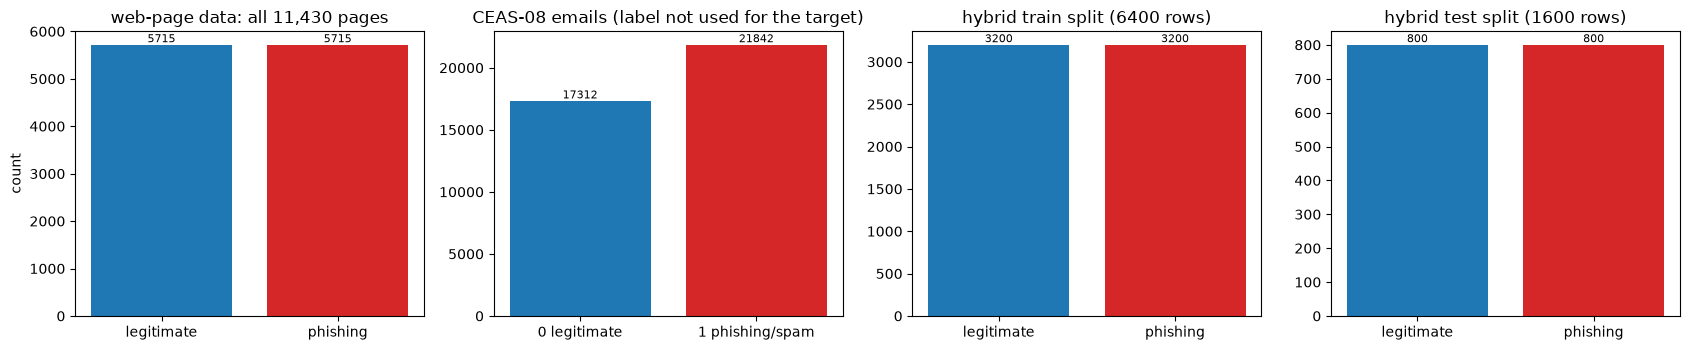

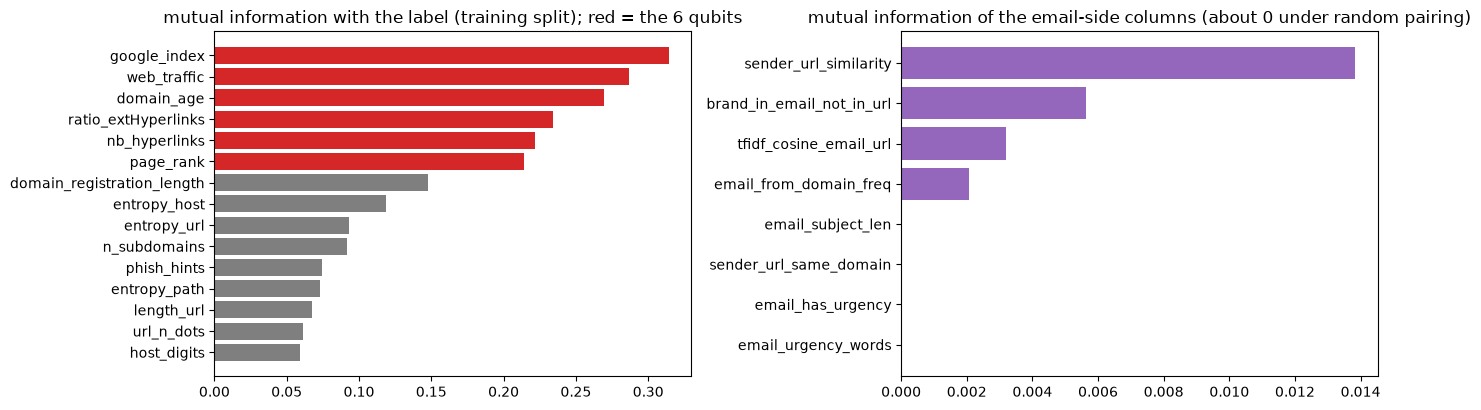

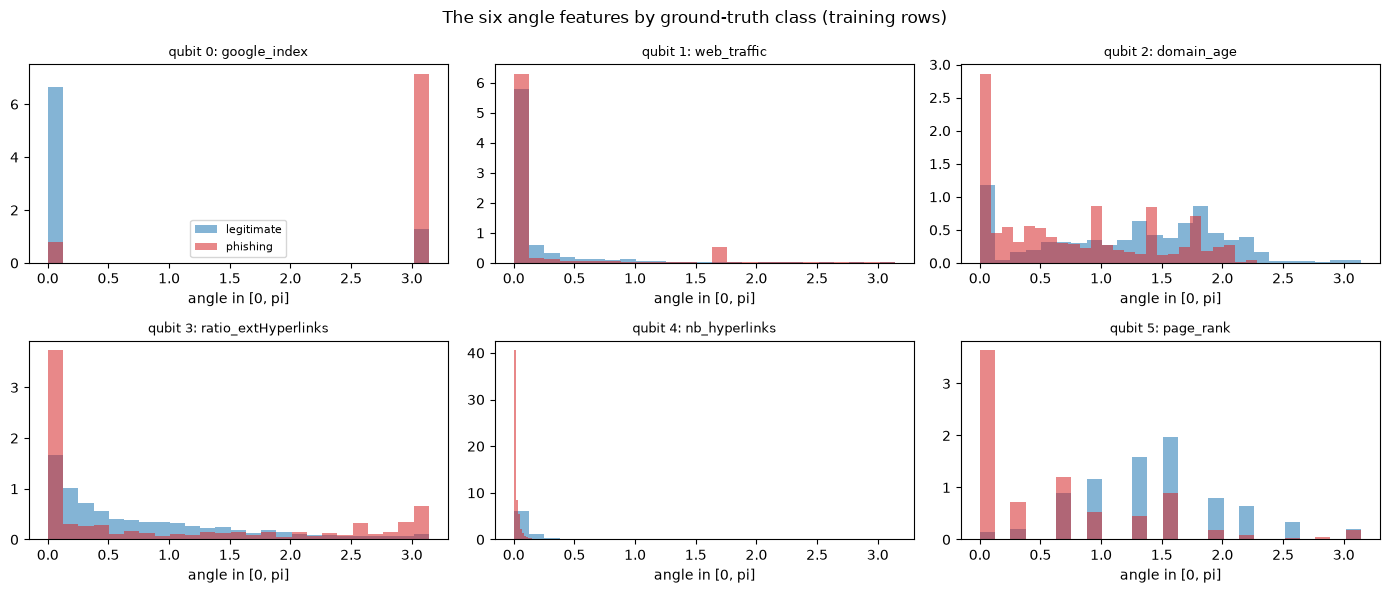

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
axes[0].bar(web_raw["status"].value_counts().index, web_raw["status"].value_counts().values, color=["#1f77b4", "#d62728"])
axes[0].set_title("web-page data: all 11,430 pages"); axes[0].set_ylabel("count")
vc = ceas_raw["label"].value_counts().sort_index()
axes[1].bar(["0 legitimate", "1 phishing/spam"], vc.values, color=["#1f77b4", "#d62728"]); axes[1].set_title("CEAS-08 emails (label not used for the target)")
for ax, y, name in [(axes[2], y_train, "train"), (axes[3], y_test, "test")]:
    ax.bar(["legitimate", "phishing"], np.bincount(y), color=["#1f77b4", "#d62728"]); ax.set_title(f"hybrid {name} split ({len(y)} rows)")
for ax in axes:
    for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

mi_top = prep["mi"].head(15)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
colors = ["#d62728" if n in prep["top_names"] else "#7f7f7f" for n in mi_top.index]
axes[0].barh(mi_top.index, mi_top.values, color=colors); axes[0].set_title("mutual information with the label (training split); red = the 6 qubits")
em_cols = [c for c in prep["mi"].index if c.startswith("email_") or c.startswith("sender_") or c.startswith("tfidf") or c.startswith("brand_in_email")]
axes[1].barh(em_cols[::-1], prep["mi"][em_cols][::-1].values, color="#9467bd"); axes[1].set_title("mutual information of the email-side columns (about 0 under random pairing)")
plt.tight_layout(); plt.show()

names = prep["top_names"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, j, n in zip(axes.ravel(), range(N_QUBITS), names):
    for cls, col, lab in [(0, "#1f77b4", "legitimate"), (1, "#d62728", "phishing")]:
        ax.hist(A_train[y_train == cls, j], bins=25, alpha=0.55, color=col, label=lab, density=True)
    ax.set_title(f"qubit {j}: {n}", fontsize=9); ax.set_xlabel("angle in [0, pi]")
axes[0, 0].legend(fontsize=8); plt.suptitle("The six angle features by ground-truth class (training rows)"); plt.tight_layout(); plt.show()

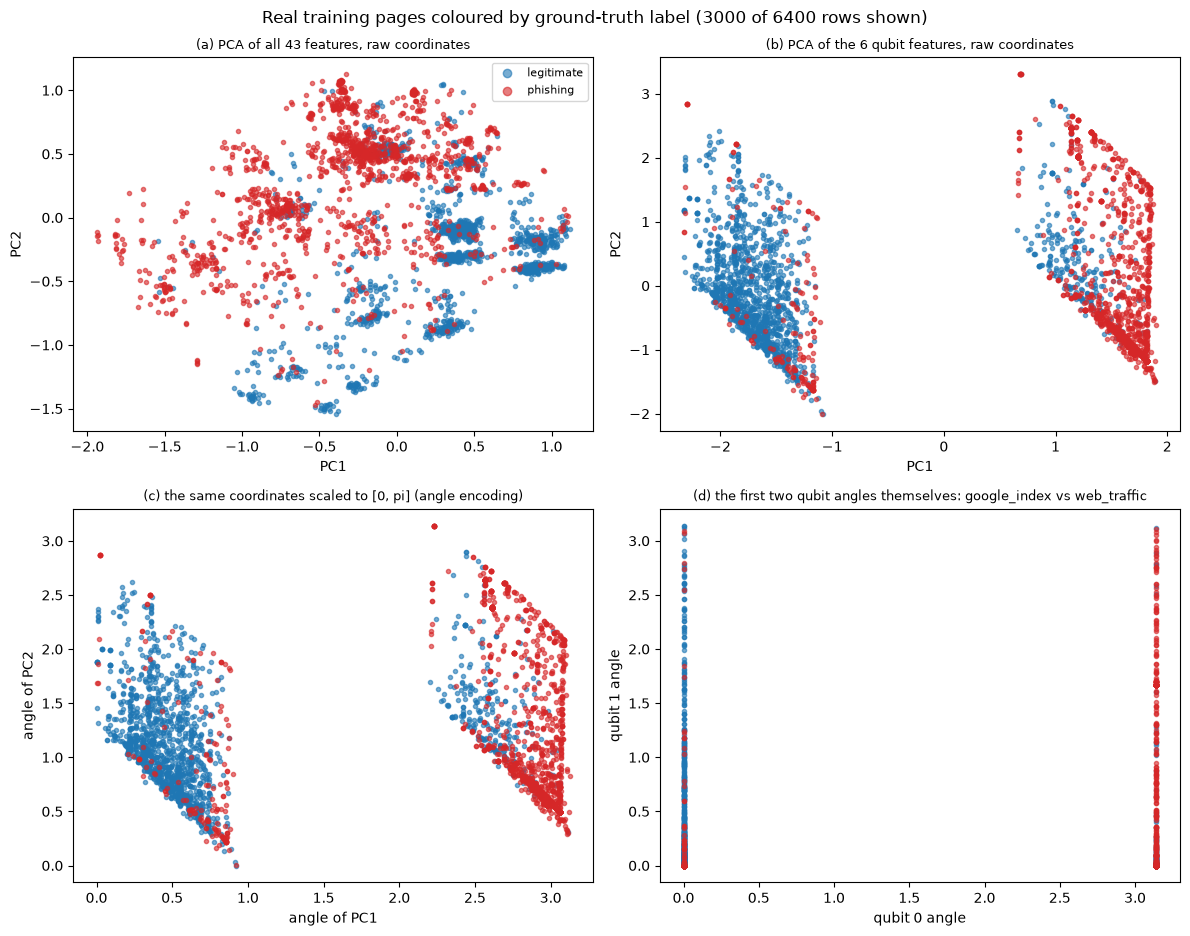

PCA variance explained: all features [0.188 0.144] | six qubit features [0.526 0.224]


In [9]:
# 2-D scatter of real training rows, coloured by the ground-truth label (modelled on the reference notebooks).
rs = np.random.default_rng(SEED)
sel = rs.choice(len(y_train), size=min(N_FIG_ROWS, len(y_train)), replace=False)
LAB = {0: ("legitimate", "#1f77b4"), 1: ("phishing", "#d62728")}

pca_all = PCA(n_components=2, random_state=SEED).fit(prep["Z_train"])                # (a) PCA of all numeric features, fitted on the training split
P_all = pca_all.transform(prep["Z_train"])
pca_sel = PCA(n_components=2, random_state=SEED).fit(A_train)                         # (b) PCA of the six qubit features, raw coordinates
P_sel = pca_sel.transform(A_train)
mm2 = MinMaxScaler((0, np.pi)).fit(P_sel); P_ang = np.clip(mm2.transform(P_sel), 0, np.pi)   # (c) the same coordinates scaled to [0, pi]

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))
panels = [(P_all, f"(a) PCA of all {prep['Z_train'].shape[1]} features, raw coordinates", "PC1", "PC2"),
          (P_sel, "(b) PCA of the 6 qubit features, raw coordinates", "PC1", "PC2"),
          (P_ang, "(c) the same coordinates scaled to [0, pi] (angle encoding)", "angle of PC1", "angle of PC2"),
          (A_train[:, :2], f"(d) the first two qubit angles themselves: {names[0]} vs {names[1]}", "qubit 0 angle", "qubit 1 angle")]
for ax, (P, title, xl, yl) in zip(axes.ravel(), panels):
    for cls in (0, 1):
        m = y_train[sel] == cls
        ax.scatter(P[sel][m, 0], P[sel][m, 1], s=9, alpha=0.6, color=LAB[cls][1], label=LAB[cls][0])
    ax.set_title(title, fontsize=9); ax.set_xlabel(xl); ax.set_ylabel(yl)
axes[0, 0].legend(fontsize=8, markerscale=2)
plt.suptitle(f"Real training pages coloured by ground-truth label ({len(sel)} of {len(y_train)} rows shown)"); plt.tight_layout(); plt.show()
print("PCA variance explained: all features", pca_all.explained_variance_ratio_.round(3), "| six qubit features", pca_sel.explained_variance_ratio_.round(3))

In [10]:
# Sanity check that the pairing really makes the email columns uninformative (a classical SVM on each block of columns).
def block_acc(cols):
    idx = [prep["columns"].index(c) for c in cols]
    m = SVC(kernel="rbf").fit(prep["Z_train"][:, idx], y_train)
    return accuracy_score(y_test, m.predict(prep["Z_test"][:, idx]))
email_cols = [c for c in prep["columns"] if c.startswith(("email_", "sender_", "tfidf", "brand_in_email"))]
web_cols = [c for c in prep["columns"] if c not in email_cols]
print(f"RBF-SVM test accuracy with the {len(web_cols)} web columns only : {block_acc(web_cols):.3f}")
print(f"RBF-SVM test accuracy with the {len(email_cols)} email columns only: {block_acc(email_cols):.3f}  (chance = 0.50 under PAIRING='random')")

RBF-SVM test accuracy with the 35 web columns only : 0.937


RBF-SVM test accuracy with the 8 email columns only: 0.548  (chance = 0.50 under PAIRING='random')


## Quantum Circuit Architecture

The QSVM's only quantum object is the feature map $|\phi(x)\rangle = U_{\Phi}(x)|0\rangle^{\otimes 6}$: a `ZZFeatureMap` on six
qubits, `reps = 1`, linear entanglement (paper Fig. 2). Qiskit defines one repetition as a Hadamard on every qubit, a phase
rotation $P(2x_i)$ on every qubit, and for each neighbouring pair $(i, i+1)$ the sequence CX - $P(2(\pi-x_i)(\pi-x_{i+1}))$ - CX.
The kernel then needs no measurement circuit of its own in the exact simulator we use: $K(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2$ is read
off the two statevectors. The paper's route (`FidelityQuantumKernel` on Aer) prepares $U(x)$, appends $U(y)^\dagger$ and measures
the probability of the all-zeros string; both routes are drawn below and shown to be numerically equal.

The paper does not give any circuit detail beyond "ZZFeatureMap, reps = 1, linear". Assumptions made here: Qiskit's default
data map $\phi_i(x)=x_i$ and $\phi_{ij}(x)=(\pi-x_i)(\pi-x_j)$, Hadamard as the first layer, no parametrised (trainable) gates -
a QSVM has **no trainable circuit parameters**: the only learned objects are the SVM dual coefficients.

feature map: qubits = 6 | data-encoding parameters = 6 | trainable parameters = 0
executed circuit (gate level): depth = 17 | size = 27 | gate counts = {'u': 17, 'cx': 10}
sample angles x: [3.142e+00 0.000e+00 2.041e+00 3.142e+00 1.000e-03 3.142e+00]


readable H/P/CX form: depth = 17 | gate counts = {'p': 11, 'cx': 10, 'h': 6} | same state as the executed circuit (assert passed)


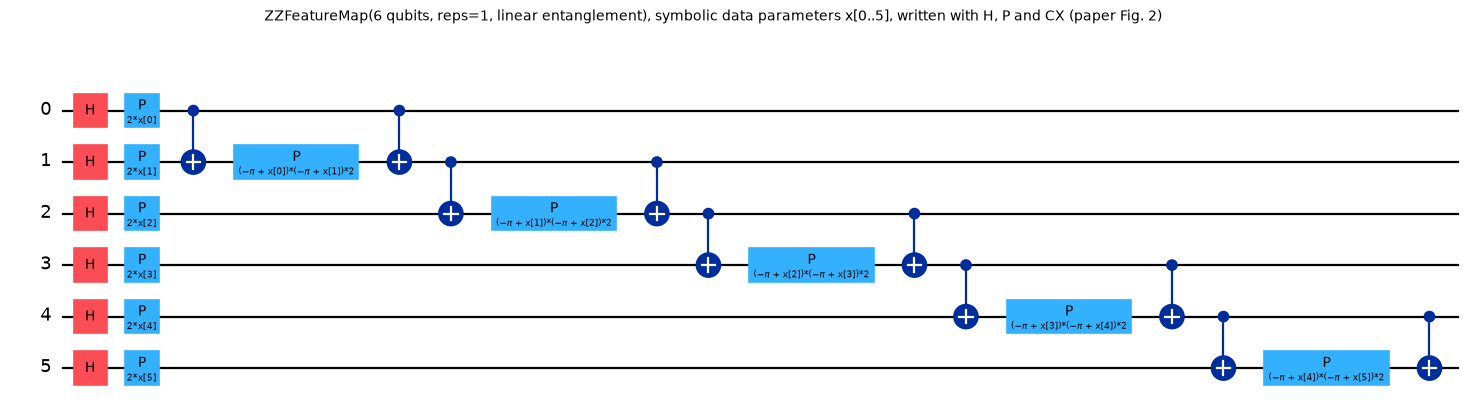

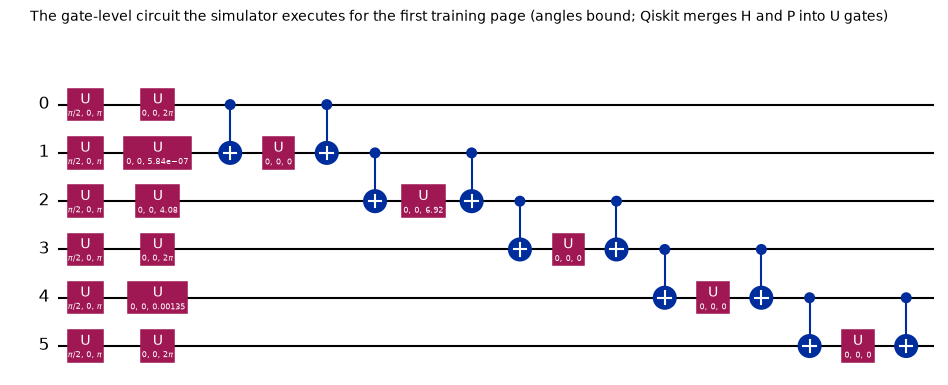

In [11]:
fm = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT)
x0, x1 = A_train[0], A_train[1]
bound0 = fm.assign_parameters(x0)
exec0 = bound0.decompose(reps=3)          # the gate-level circuit that the statevector simulator evolves

print("feature map: qubits =", fm.num_qubits, "| data-encoding parameters =", fm.num_parameters, "| trainable parameters = 0")
print("executed circuit (gate level): depth =", exec0.depth(), "| size =", exec0.size(), "| gate counts =", dict(exec0.count_ops()))
print("sample angles x:", np.round(x0, 3))

readable = transpile(fm, basis_gates=["h", "p", "cx"], optimization_level=0)      # the same circuit written with H, P and CX gates
assert Statevector(readable.assign_parameters(x0)).equiv(Statevector(exec0))          # identical state up to a global phase
print("readable H/P/CX form: depth =", readable.depth(), "| gate counts =", dict(readable.count_ops()), "| same state as the executed circuit (assert passed)")
fig = readable.draw("mpl", fold=-1, scale=0.8)
fig.suptitle("ZZFeatureMap(6 qubits, reps=1, linear entanglement), symbolic data parameters x[0..5], written with H, P and CX (paper Fig. 2)", y=1.02, fontsize=10)
display(fig); plt.close(fig)
fig = exec0.draw("mpl", fold=-1, scale=0.75)
fig.suptitle("The gate-level circuit the simulator executes for the first training page (angles bound; Qiskit merges H and P into U gates)", y=1.02, fontsize=10)
display(fig); plt.close(fig)

fidelity-kernel circuit: qubits = 6 | depth = 35 | gate counts = {'u': 34, 'cx': 20, 'measure': 6, 'barrier': 1}


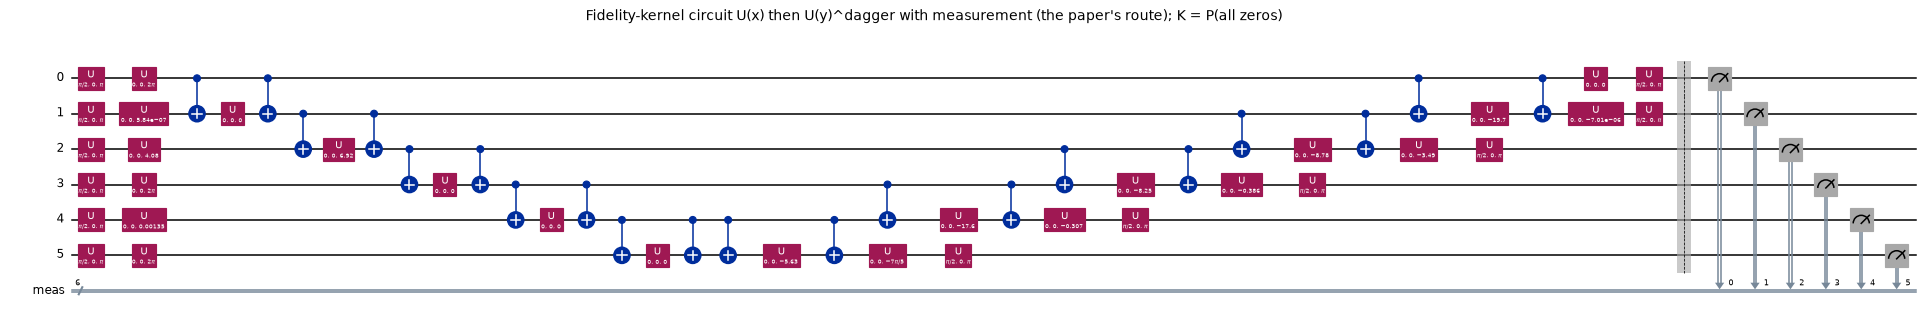

pair (0,1): P(0...0) = 0.016181 | |<phi|phi>|^2 = 0.016181 | FidelityStatevectorKernel = 0.016181
pair (2,3): P(0...0) = 0.096118 | |<phi|phi>|^2 = 0.096118 | FidelityStatevectorKernel = 0.096118
pair (4,5): P(0...0) = 0.014528 | |<phi|phi>|^2 = 0.014528 | FidelityStatevectorKernel = 0.014528
pair (6,7): P(0...0) = 0.061133 | |<phi|phi>|^2 = 0.061133 | FidelityStatevectorKernel = 0.061133
pair (0,0): P(0...0) = 1.000000 | |<phi|phi>|^2 = 1.000000 | FidelityStatevectorKernel = 1.000000
the circuit route of the paper and the statevector kernel used below agree (assert passed).


In [12]:
# The paper's kernel circuit (FidelityQuantumKernel on Aer): U(x) followed by U(y)^dagger, then measure all qubits.
kernel_circ = fm.assign_parameters(x0).compose(fm.assign_parameters(x1).inverse())
kernel_circ_m = kernel_circ.copy(); kernel_circ_m.measure_all()
dec = kernel_circ_m.decompose(reps=3)
print("fidelity-kernel circuit: qubits =", dec.num_qubits, "| depth =", dec.depth(), "| gate counts =", dict(dec.count_ops()))
fig = dec.draw("mpl", fold=60, scale=0.55)
fig.suptitle("Fidelity-kernel circuit U(x) then U(y)^dagger with measurement (the paper's route); K = P(all zeros)", y=1.0, fontsize=10)
display(fig); plt.close(fig)

# Equivalence: the all-zeros probability of this circuit equals |<phi(x)|phi(y)>|^2 equals what the Qiskit kernel returns.
kern = FidelityStatevectorKernel(feature_map=fm, auto_clear_cache=False)
pairs = [(0, 1), (2, 3), (4, 5), (6, 7), (0, 0)]
for i, j in pairs:
    circ = fm.assign_parameters(A_train[i]).compose(fm.assign_parameters(A_train[j]).inverse())
    p0 = Statevector(circ).probabilities()[0]
    k_overlap = abs(np.vdot(Statevector(fm.assign_parameters(A_train[i])).data, Statevector(fm.assign_parameters(A_train[j])).data)) ** 2
    k_qiskit = kern.evaluate(A_train[i:i+1], A_train[j:j+1])[0, 0]
    assert np.allclose([p0, k_overlap], k_qiskit, atol=1e-9), (i, j, p0, k_overlap, k_qiskit)
    print(f"pair ({i},{j}): P(0...0) = {p0:.6f} | |<phi|phi>|^2 = {k_overlap:.6f} | FidelityStatevectorKernel = {k_qiskit:.6f}")
print("the circuit route of the paper and the statevector kernel used below agree (assert passed).")

## 4. Reference classifiers on the identical six angles

Before the batch ensembles, three single models are trained on the **whole** training split with exactly the six angles the
quantum kernel sees: the paper's RBF-SVM (balanced class weights, `C = 1`, `gamma = "scale"`), a random forest, and the same RBF-SVM on
all numeric features. They show how much the six-feature bottleneck costs and what the batch ensembles have to beat.

In [13]:
def metrics(y_true, y_pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = dict(accuracy=accuracy_score(y_true, y_pred), precision=precision_score(y_true, y_pred, zero_division=0),
               recall=recall_score(y_true, y_pred, zero_division=0), f1=f1_score(y_true, y_pred, zero_division=0),
               fn=int(fn), fp=int(fp), tp=int(tp), tn=int(tn))
    out["auc"] = roc_auc_score(y_true, score) if score is not None else np.nan
    return out

def fit_eval(model, Xtr, ytr, Xte, yte, name):
    t0 = time.perf_counter(); model.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(Xte); t_pred = time.perf_counter() - t0
    score = model.decision_function(Xte) if hasattr(model, "decision_function") else model.predict_proba(Xte)[:, 1]
    return dict(model=name, fit_s=t_fit, predict_s=t_pred, **metrics(yte, pred, score))

single_rows = [
    fit_eval(SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA, class_weight="balanced", random_state=SEED), A_train, y_train, A_test, y_test, "SVM rbf (6 angles, full train set)"),
    fit_eval(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), A_train, y_train, A_test, y_test, "RandomForest (6 angles, full train set)"),
    fit_eval(SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA, class_weight="balanced", random_state=SEED), prep["Z_train"], y_train, prep["Z_test"], y_test, f"SVM rbf (all {prep['Z_train'].shape[1]} features)"),
]
single_df = pd.DataFrame(single_rows)
display(single_df.round(4))

,model,fit_s,predict_s,accuracy,precision,recall,f1,fn,fp,tp,tn,auc
0,"SVM rbf (6 angles, full train set)",1.0622,0.6556,0.8938,0.8870,0.9025,0.8947,78,92,722,708,0.9628
1,"RandomForest (6 angles, full train set)",2.7578,0.1217,0.9306,0.9269,0.9350,0.9309,52,59,748,741,0.9799
2,SVM rbf (all 43 features),2.5423,0.7383,0.9338,0.9415,0.9250,0.9332,60,46,740,754,0.9790


## 5. Batch-wise training and majority voting (paper Section IV.A.3-4 and IV.D)

The training rows are already shuffled, so cutting them into consecutive slices of `BATCH_SIZE` gives batches with both classes
(the paper: "fixed-size batches ... due to prior shuffling"). For each batch a **fresh** classical SVM and a **fresh** QSVM are
fitted on the same six angles; both predict the shared test set; the final label is the majority of the batch votes. A QSVM batch
model is `QSVC(quantum_kernel=<FidelityStatevectorKernel on zz_feature_map(6, reps=1, linear)>)`. The kernel object is re-used
across batches only as a *cache of statevectors* (a statevector is a deterministic function of the six angles, so the cache cannot
carry information between batches); every `QSVC` and every `SVC` is new.

In [14]:
def make_batches(n, size, max_batches=None):
    sl = [np.arange(s, min(s + size, n)) for s in range(0, n, size)]       # consecutive slices of the (already shuffled) training rows
    return sl[:max_batches] if max_batches else sl

def majority(votes, tie=TIE_GOES_TO):
    frac = votes.mean(axis=0)
    pred = (frac > 0.5).astype(int)
    pred[frac == 0.5] = tie
    return pred, frac

class VectorisedFidelityStatevectorKernel(FidelityStatevectorKernel):
    """Qiskit's FidelityStatevectorKernel (exact K = |<phi(x)|phi(y)>|^2) with one change: the Gram matrix is computed as a single
    matrix product of the statevectors instead of a Python loop over pairs (Qiskit's loop costs minutes for a 500 x 1,600 block).
    The statevectors are cached by their input angles; a statevector is a deterministic function of the angles, so the cache cannot
    carry information from one batch to another. Equality with the original class is asserted in the next cell."""
    def __init__(self, *, feature_map, **kwargs):
        super().__init__(feature_map=feature_map, auto_clear_cache=False, **kwargs)
        self._gate_circuit = feature_map.decompose(reps=3)
        self._sv_cache = {}
    def _embed(self, X):
        X = np.ascontiguousarray(np.atleast_2d(X), dtype=float)
        out = np.empty((len(X), 2 ** self._gate_circuit.num_qubits), dtype=complex)
        for i, x in enumerate(X):
            key = x.tobytes()
            if key not in self._sv_cache:
                self._sv_cache[key] = Statevector(self._gate_circuit.assign_parameters(x)).data
            out[i] = self._sv_cache[key]
        return out
    def evaluate(self, x_vec, y_vec=None):
        SX = self._embed(x_vec); SY = SX if y_vec is None else self._embed(y_vec)
        return np.abs(SX @ SY.conj().T) ** 2

SHARED_KERNEL = VectorisedFidelityStatevectorKernel(feature_map=fm)      # statevector cache only; models are re-created per batch

def run_ensemble(A_tr, y_tr, A_te, y_te, batches, bw=1.0, gamma=SVM_GAMMA, C_svm=SVM_C, C_qsvm=1.0, verbose=True):
    """One SVM and one QSVM per batch, majority vote. bw rescales the angles for the QSVM (paper: 1.0)."""
    rows, votes_s, votes_q, dec_q, dec_s = [], [], [], [], []
    for b, idx in enumerate(batches):
        Xb, yb = A_tr[idx], y_tr[idx]
        t0 = time.perf_counter()
        svm = SVC(kernel="rbf", C=C_svm, gamma=gamma, class_weight="balanced", random_state=SEED).fit(Xb, yb)
        p_s = svm.predict(A_te); t_s = time.perf_counter() - t0
        t0 = time.perf_counter()
        qsvm = QSVC(quantum_kernel=SHARED_KERNEL, C=C_qsvm).fit(bw * Xb, yb)
        p_q = qsvm.predict(bw * A_te); t_q = time.perf_counter() - t0
        votes_s.append(p_s); votes_q.append(p_q); dec_s.append(svm.decision_function(A_te)); dec_q.append(qsvm.decision_function(bw * A_te))
        rows.append(dict(batch=b + 1, n=len(idx), svm_acc=accuracy_score(y_te, p_s), qsvm_acc=accuracy_score(y_te, p_q),
                         svm_fn=int(((p_s == 0) & (y_te == 1)).sum()), qsvm_fn=int(((p_q == 0) & (y_te == 1)).sum()),
                         svm_s=t_s, qsvm_s=t_q))
        if verbose:
            r = rows[-1]; print(f"batch {r['batch']:2d} (n={r['n']}): SVM acc {r['svm_acc']:.4f} FN {r['svm_fn']:3d} {r['svm_s']:.2f}s | QSVM acc {r['qsvm_acc']:.4f} FN {r['qsvm_fn']:3d} {r['qsvm_s']:.1f}s")
    votes_s, votes_q = np.array(votes_s), np.array(votes_q)
    pred_s, frac_s = majority(votes_s); pred_q, frac_q = majority(votes_q)
    return dict(batch_df=pd.DataFrame(rows), votes_s=votes_s, votes_q=votes_q, pred_s=pred_s, pred_q=pred_q, frac_s=frac_s, frac_q=frac_q,
                dec_s=np.mean(dec_s, axis=0), dec_q=np.mean(dec_q, axis=0))

batches = make_batches(len(y_train), BATCH_SIZE, MAX_BATCHES)
print(f"{len(y_train)} training rows -> {len(batches)} batches of {BATCH_SIZE} (sizes {[len(b) for b in batches]}) | {len(A_test)} test rows")
t0 = time.time()
ens = run_ensemble(A_train, y_train, A_test, y_test, batches)
T_ENS = time.time() - t0
print(f"ensembles done in {T_ENS/60:.1f} min")

6400 training rows -> 13 batches of 500 (sizes [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 400]) | 1600 test rows


batch  1 (n=500): SVM acc 0.8881 FN 104 0.07s | QSVM acc 0.7919 FN 201 8.5s


batch  2 (n=500): SVM acc 0.8856 FN  94 0.05s | QSVM acc 0.8250 FN 166 1.7s


batch  3 (n=500): SVM acc 0.8875 FN  89 0.05s | QSVM acc 0.8219 FN 173 1.6s


batch  4 (n=500): SVM acc 0.8894 FN  93 0.05s | QSVM acc 0.8194 FN 156 1.7s


...

batch  9 (n=500): SVM acc 0.8894 FN 103 0.06s | QSVM acc 0.8094 FN 177 1.5s


batch 10 (n=500): SVM acc 0.8662 FN  78 0.05s | QSVM acc 0.8019 FN 155 1.4s


batch 11 (n=500): SVM acc 0.8906 FN  97 0.07s | QSVM acc 0.7963 FN 204 1.5s


batch 12 (n=500): SVM acc 0.8956 FN  93 0.07s | QSVM acc 0.7650 FN 219 2.3s


batch 13 (n=400): SVM acc 0.8825 FN  95 0.05s | QSVM acc 0.8106 FN 151 1.4s
ensembles done in 0.5 min


### The statevector kernel is the paper's fidelity kernel

The paper reports hours for the QSVM because every kernel entry is a separate Aer circuit. The kernel *values* do not depend on how
they are simulated. The cell below recomputes the kernel of one batch by hand from statevectors, $|\langle\phi(a)|\phi(b)\rangle|^2$, and checks
that it matches the kernel matrix of the Qiskit object that the `QSVC`s used, and that an SVM with that precomputed kernel makes the same predictions as the `QSVC`.

In [15]:
idx = batches[0][:80]
S = np.array([Statevector(fm.assign_parameters(a)).data for a in A_train[idx]])
K_hand = np.abs(S @ S.conj().T) ** 2
K_qiskit = SHARED_KERNEL.evaluate(A_train[idx])
K_orig = FidelityStatevectorKernel(feature_map=fm).evaluate(A_train[idx[:30]])       # Qiskit's own loop-based class on a 30-row block
print("max |hand kernel - vectorised kernel| =", np.abs(K_hand - K_qiskit).max(), "| max |Qiskit original - vectorised| (30 rows) =", np.abs(K_orig - K_qiskit[:30, :30]).max())
assert np.allclose(K_hand, K_qiskit, atol=1e-9) and np.allclose(K_orig, K_qiskit[:30, :30], atol=1e-9)
ref = SVC(kernel="precomputed").fit(K_hand, y_train[idx])
S_te = np.array([Statevector(fm.assign_parameters(a)).data for a in A_test[:200]])
pred_ref = ref.predict(np.abs(S_te @ S.conj().T) ** 2)
pred_qsvc = QSVC(quantum_kernel=SHARED_KERNEL).fit(A_train[idx], y_train[idx]).predict(A_test[:200])
print("precomputed-kernel SVC and QSVC give the same predictions on 200 test pages:", bool((pred_ref == pred_qsvc).all()))
assert (pred_ref == pred_qsvc).all()

max |hand kernel - vectorised kernel| = 6.439293542825908e-15 | max |Qiskit original - vectorised| (30 rows) = 4.440892098500626e-15


precomputed-kernel SVC and QSVC give the same predictions on 200 test pages: True


## 6. Results: the paper's Table I and Figures 3 - 6

Positive class = phishing. A false negative is a phishing page predicted legitimate. The ROC-AUC of an ensemble is computed from the
fraction of batch models that vote "phishing".

In [16]:
res_s = metrics(y_test, ens["pred_s"], ens["frac_s"]); res_q = metrics(y_test, ens["pred_q"], ens["frac_q"])
tbl = pd.DataFrame({"Classical SVM ensemble": res_s, "QSVM ensemble": res_q}).T
tbl["fn_rate"] = tbl["fn"] / (tbl["fn"] + tbl["tp"])
display(tbl[["accuracy", "precision", "recall", "f1", "auc", "fn", "fp", "tp", "tn"]].round(4))
fn_s, fn_q = res_s["fn"], res_q["fn"]
fn_red = 100 * (fn_s - fn_q) / fn_s if fn_s else float("nan")
print(f"false negatives: SVM {fn_s} -> QSVM {fn_q}  ({fn_red:+.0f} % reduction; paper: 29 -> 6, 79 %)")

bdf = ens["batch_df"]
print(f"\nbatch-wise accuracy over {len(bdf)} batches (each model alone on the shared test set):")
print(f"  SVM  : min {bdf.svm_acc.min():.3f} max {bdf.svm_acc.max():.3f} mean {bdf.svm_acc.mean():.3f} sigma {bdf.svm_acc.std(ddof=0):.4f}   (paper 0.955-0.987, sigma ~0.009)")
print(f"  QSVM : min {bdf.qsvm_acc.min():.3f} max {bdf.qsvm_acc.max():.3f} mean {bdf.qsvm_acc.mean():.3f} sigma {bdf.qsvm_acc.std(ddof=0):.4f}   (paper 0.960-0.983, sigma ~0.007)")
print(f"time per batch: SVM {bdf.svm_s.mean():.2f} s, QSVM {bdf.qsvm_s.mean():.1f} s (ratio {bdf.qsvm_s.mean()/max(bdf.svm_s.mean(),1e-9):.0f}x; paper 0.20 s vs ~1,100 s, ~5,500x)")
print(f"total training+prediction: SVM {bdf.svm_s.sum():.1f} s, QSVM {bdf.qsvm_s.sum()/60:.1f} min (paper 2.6 s vs ~240 min)")
display(bdf.round(4))

,accuracy,precision,recall,f1,auc,fn,fp,tp,tn
Classical SVM ensemble,0.8875,0.8974,0.8750,0.8861,0.9180,100.0,80.0,700.0,720.0
QSVM ensemble,0.8481,0.8789,0.8075,0.8417,0.9098,154.0,89.0,646.0,711.0


false negatives: SVM 100 -> QSVM 154  (-54 % reduction; paper: 29 -> 6, 79 %)

batch-wise accuracy over 13 batches (each model alone on the shared test set):
  SVM  : min 0.866 max 0.896 mean 0.886 sigma 0.0069   (paper 0.955-0.987, sigma ~0.009)
  QSVM : min 0.765 max 0.825 mean 0.803 sigma 0.0150   (paper 0.960-0.983, sigma ~0.007)
time per batch: SVM 0.06 s, QSVM 2.2 s (ratio 37x; paper 0.20 s vs ~1,100 s, ~5,500x)
total training+prediction: SVM 0.8 s, QSVM 0.5 min (paper 2.6 s vs ~240 min)


,batch,n,svm_acc,qsvm_acc,svm_fn,qsvm_fn,svm_s,qsvm_s
0,1,500,0.8881,0.7919,104,201,0.0700,8.5172
1,2,500,0.8856,0.8250,94,166,0.0504,1.6779
2,3,500,0.8875,0.8219,89,173,0.0523,1.5943
3,4,500,0.8894,0.8194,93,156,0.0528,1.6513
4,5,500,0.8931,0.8000,90,173,0.0699,1.5889
5,6,500,0.8862,0.8025,96,197,0.0572,1.7397
6,7,500,0.8806,0.7938,121,207,0.0442,1.6305
7,8,500,0.8869,0.7981,104,198,0.0649,1.5607
8,9,500,0.8894,0.8094,103,177,0.0585,1.4510
9,10,500,0.8662,0.8019,78,155,0.0540,1.4488


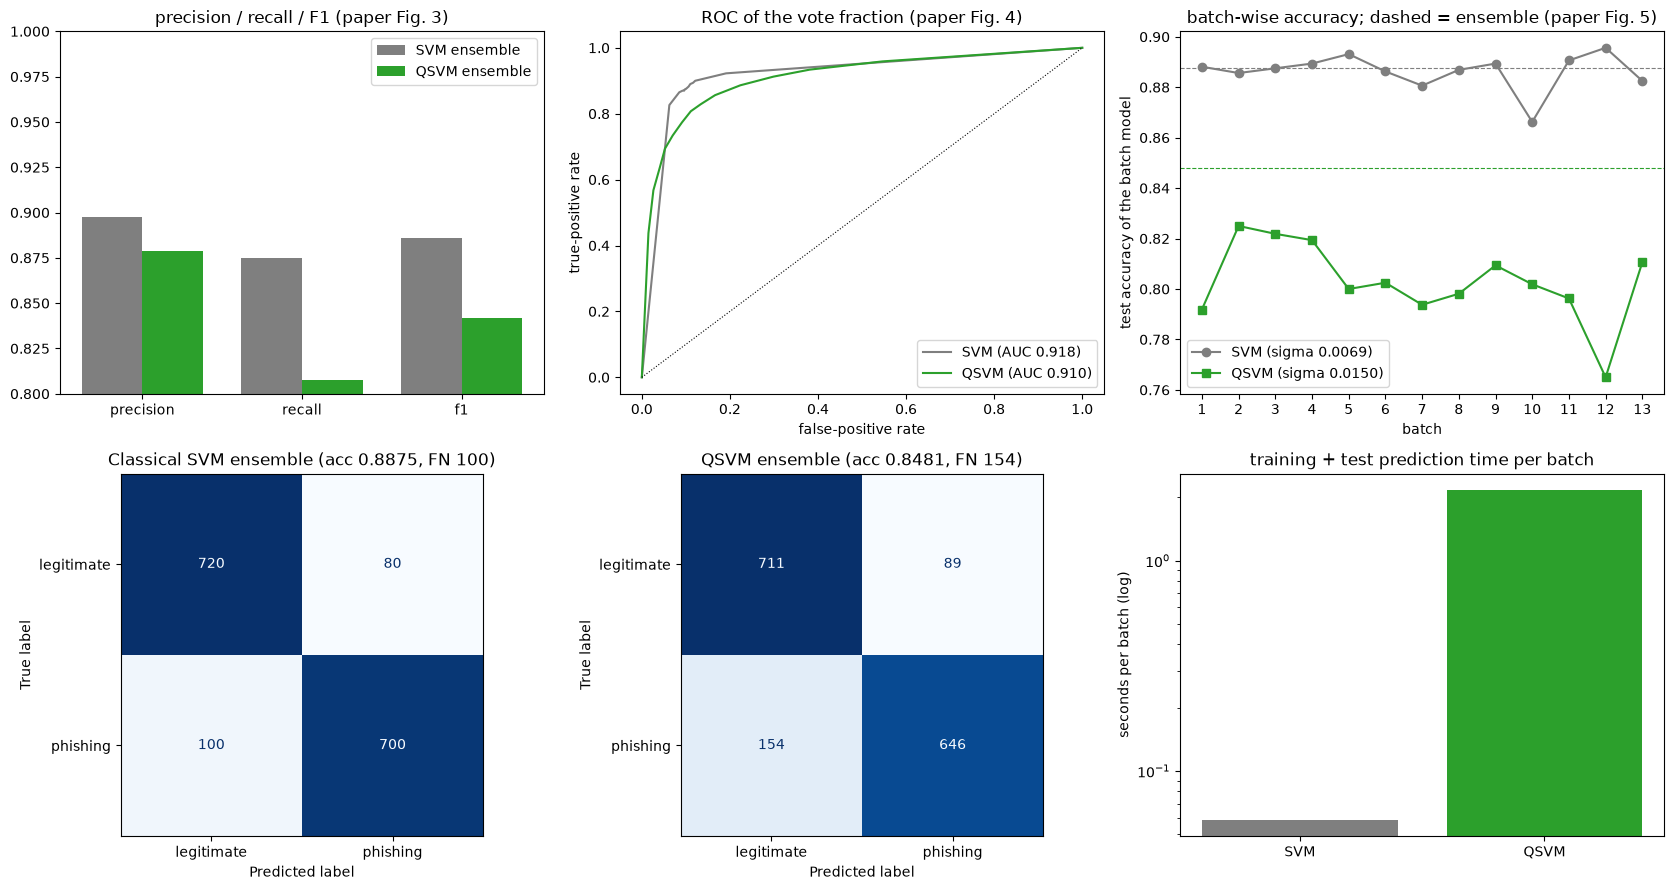

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
# Fig. 3: precision / recall / F1
ax = axes[0, 0]; labs = ["precision", "recall", "f1"]; w = 0.38; xs = np.arange(3)
ax.bar(xs - w/2, [res_s[k] for k in labs], w, label="SVM ensemble", color="#7f7f7f"); ax.bar(xs + w/2, [res_q[k] for k in labs], w, label="QSVM ensemble", color="#2ca02c")
ax.set_xticks(xs); ax.set_xticklabels(labs); ax.set_ylim(min(0.8, min(res_s[k] for k in labs)-0.02), 1.0); ax.legend(); ax.set_title("precision / recall / F1 (paper Fig. 3)")
# Fig. 4: ROC
ax = axes[0, 1]
for name, frac, col in [("SVM", ens["frac_s"], "#7f7f7f"), ("QSVM", ens["frac_q"], "#2ca02c")]:
    fpr, tpr, _ = roc_curve(y_test, frac); ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {roc_auc_score(y_test, frac):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.legend(); ax.set_title("ROC of the vote fraction (paper Fig. 4)")
# Fig. 5: batch-wise accuracy
ax = axes[0, 2]
ax.plot(bdf.batch, bdf.svm_acc, "o-", color="#7f7f7f", label=f"SVM (sigma {bdf.svm_acc.std(ddof=0):.4f})"); ax.plot(bdf.batch, bdf.qsvm_acc, "s-", color="#2ca02c", label=f"QSVM (sigma {bdf.qsvm_acc.std(ddof=0):.4f})")
ax.axhline(res_s["accuracy"], color="#7f7f7f", ls="--", lw=0.8); ax.axhline(res_q["accuracy"], color="#2ca02c", ls="--", lw=0.8)
ax.set_xticks(bdf.batch.tolist()); ax.set_xlabel("batch"); ax.set_ylabel("test accuracy of the batch model"); ax.legend(); ax.set_title("batch-wise accuracy; dashed = ensemble (paper Fig. 5)")
# Fig. 6: confusion matrices
for ax, name, pred in [(axes[1, 0], "Classical SVM ensemble", ens["pred_s"]), (axes[1, 1], "QSVM ensemble", ens["pred_q"])]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]), display_labels=["legitimate", "phishing"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} (acc {accuracy_score(y_test, pred):.4f}, FN {int(((pred==0)&(y_test==1)).sum())})")
# timing
ax = axes[1, 2]; ax.bar(["SVM", "QSVM"], [bdf.svm_s.mean(), bdf.qsvm_s.mean()], color=["#7f7f7f", "#2ca02c"]); ax.set_yscale("log"); ax.set_ylabel("seconds per batch (log)")
ax.set_title("training + test prediction time per batch")
plt.tight_layout(); plt.show()

## 7. Checks the paper lists as future work, and fairness extras

The paper's Conclusion asks for **statistical significance testing (McNemar)** and an **ablation** of ensembling versus the quantum kernel. Both
are cheap here. (i) McNemar's exact test on the paired test-set errors of the two ensembles. (ii) The same RBF-SVM ensemble is the "classical
twin" of the QSVM; additionally the single full-train SVM of Section 4 shows whether *ensembling over 500-row batches* costs or helps. (iii) Both
families get the same validation-based tuning on the training data (kernel bandwidth of the quantum kernel; `C` and `gamma` of the RBF
kernel) because the paper tunes neither, so "QSVM better" could just mean "better default bandwidth". (iv) With the full settings the whole pipeline
(new hybrid draw, new split, new features) is repeated for `EXTRA_SEEDS` to give mean +- std.

In [18]:
# (i) McNemar exact test on paired errors of the two ensembles (test set shared)
def mcnemar(y, p1, p2):
    e1, e2 = (p1 != y), (p2 != y)
    b = int((e1 & ~e2).sum()); c = int((~e1 & e2).sum())      # b: SVM wrong, QSVM right; c: SVM right, QSVM wrong
    p = 1.0 if b + c == 0 else binomtest(min(b, c), b + c, 0.5).pvalue
    return b, c, p
b, c, p = mcnemar(y_test, ens["pred_s"], ens["pred_q"])
print(f"McNemar (SVM ensemble vs QSVM ensemble): SVM wrong & QSVM right = {b}, SVM right & QSVM wrong = {c}, exact two-sided p = {p:.4f}")
print("ensembles predict identically on", int((ens["pred_s"] == ens["pred_q"]).sum()), "of", len(y_test), "test pages")

McNemar (SVM ensemble vs QSVM ensemble): SVM wrong & QSVM right = 104, SVM right & QSVM wrong = 167, exact two-sided p = 0.0002
ensembles predict identically on 1329 of 1600 test pages


In [19]:
# (iii) tuned versions, chosen on a validation split of the TRAINING data only (the test split is not touched)
tuned = None
if RUN_TUNED_EXTRA:
    rs = np.random.default_rng(SEED); order = rs.permutation(len(y_train))
    n_in = min(BATCH_SIZE, len(order) // 2); n_val = min(BATCH_SIZE, len(order) - n_in)
    i_tr, i_val = order[:n_in], order[n_in:n_in + n_val]
    best_s = max(((accuracy_score(y_train[i_val], SVC(kernel="rbf", C=C_, gamma=g, class_weight="balanced").fit(A_train[i_tr], y_train[i_tr]).predict(A_train[i_val])), C_, g)
                  for C_ in C_GRID for g in GAMMA_GRID), key=lambda t: t[0])
    val_q = {}
    for bw in BW_GRID:
        m = QSVC(quantum_kernel=SHARED_KERNEL).fit(bw * A_train[i_tr], y_train[i_tr])
        val_q[bw] = accuracy_score(y_train[i_val], m.predict(bw * A_train[i_val]))
    bw_best = max(val_q, key=val_q.get)
    print(f"tuned SVM  : C={best_s[1]}, gamma={best_s[2]} (validation accuracy {best_s[0]:.4f})")
    print(f"tuned QSVM : bandwidth {bw_best} (validation accuracy by bandwidth {({k: round(v, 4) for k, v in val_q.items()})})")
    ens_t = run_ensemble(A_train, y_train, A_test, y_test, batches, bw=bw_best, gamma=best_s[2], C_svm=best_s[1], verbose=False)
    r_s, r_q = metrics(y_test, ens_t["pred_s"], ens_t["frac_s"]), metrics(y_test, ens_t["pred_q"], ens_t["frac_q"])
    tuned = dict(bw=bw_best, svm=r_s, qsvm=r_q, ens=ens_t)
    display(pd.DataFrame({"tuned SVM ensemble": r_s, "tuned QSVM ensemble": r_q}).T[["accuracy", "precision", "recall", "f1", "auc", "fn", "fp"]].round(4))
else:
    print("RUN_TUNED_EXTRA = False: skipped")

tuned SVM  : C=1.0, gamma=0.3 (validation accuracy 0.9160)
tuned QSVM : bandwidth 0.25 (validation accuracy by bandwidth {0.1: 0.906, 0.25: 0.91, 0.5: 0.896, 1.0: 0.804})


,accuracy,precision,recall,f1,auc,fn,fp
tuned SVM ensemble,0.8900,0.8990,0.8788,0.8887,0.9263,97.0,79.0
tuned QSVM ensemble,0.8962,0.8962,0.8962,0.8962,0.9428,83.0,83.0


In [20]:
# (iv) repeat the whole pipeline for other seeds (new hybrid draw, split, features, mutual information, batches)
seed_rows = [dict(seed=SEED, **{f"svm_{k}": res_s[k] for k in ("accuracy", "recall", "f1", "auc", "fn")}, **{f"qsvm_{k}": res_q[k] for k in ("accuracy", "recall", "f1", "auc", "fn")})]
for sd in EXTRA_SEEDS:
    t0 = time.time()
    hyb_s = make_hybrid(sd); tr_s, te_s = split_hybrid(hyb_s, sd); ytr_s, yte_s = tr_s["y"].to_numpy(), te_s["y"].to_numpy()
    pr = preprocess(tr_s, te_s, ytr_s, seed=sd)
    bt = make_batches(len(ytr_s), BATCH_SIZE, MAX_BATCHES)
    e = run_ensemble(pr["A_train"], ytr_s, pr["A_test"], yte_s, bt, verbose=False)
    a, q = metrics(yte_s, e["pred_s"], e["frac_s"]), metrics(yte_s, e["pred_q"], e["frac_q"])
    seed_rows.append(dict(seed=sd, **{f"svm_{k}": a[k] for k in ("accuracy", "recall", "f1", "auc", "fn")}, **{f"qsvm_{k}": q[k] for k in ("accuracy", "recall", "f1", "auc", "fn")}))
    print(f"seed {sd}: selected {pr['top_names']} | SVM acc {a['accuracy']:.4f} FN {a['fn']} | QSVM acc {q['accuracy']:.4f} FN {q['fn']} | {(time.time()-t0)/60:.1f} min")
seed_df = pd.DataFrame(seed_rows)
display(seed_df.round(4))
if len(seed_df) > 1:
    print("mean +- std over seeds:")
    display(pd.DataFrame({"mean": seed_df.drop(columns="seed").mean(), "std": seed_df.drop(columns="seed").std(ddof=0)}).round(4).T)

seed 43: selected ['google_index', 'web_traffic', 'domain_age', 'ratio_extHyperlinks', 'nb_hyperlinks', 'page_rank'] | SVM acc 0.9069 FN 79 | QSVM acc 0.8425 FN 159 | 0.8 min


seed 44: selected ['google_index', 'web_traffic', 'domain_age', 'nb_hyperlinks', 'ratio_extHyperlinks', 'page_rank'] | SVM acc 0.8838 FN 102 | QSVM acc 0.8200 FN 161 | 1.0 min


,seed,svm_accuracy,svm_recall,svm_f1,svm_auc,svm_fn,qsvm_accuracy,qsvm_recall,qsvm_f1,qsvm_auc,qsvm_fn
0,42,0.8875,0.8750,0.8861,0.9180,100,0.8481,0.8075,0.8417,0.9098,154
1,43,0.9069,0.9012,0.9063,0.9389,79,0.8425,0.8012,0.8357,0.9222,159
2,44,0.8838,0.8725,0.8824,0.9128,102,0.8200,0.7988,0.8161,0.9031,161


mean +- std over seeds:


,svm_accuracy,svm_recall,svm_f1,svm_auc,svm_fn,qsvm_accuracy,qsvm_recall,qsvm_f1,qsvm_auc,qsvm_fn
mean,0.8927,0.8829,0.8916,0.9232,93.6667,0.8369,0.8025,0.8312,0.9117,158.0000
std,0.0101,0.0130,0.0105,0.0113,10.4030,0.0122,0.0037,0.0109,0.0079,2.9439


## 8. Paper versus this notebook

Verdict rule (as in the other notebooks of this project): **reproduced** when our value is within 0.02 of the paper's (two accuracy
points; 0.02 in F1 / AUC), **exceeded** above and **not reached** below that band; directional claims are checked by sign; claims that depend
on hardware or on data we do not have are marked **cannot be checked**. The headline column is the paper-faithful setting (bandwidth 1, default `C`).

In [21]:
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")

rows = []
for name, paper_s, paper_q, key in [("Accuracy", 0.9770, 0.9879, "accuracy"), ("Recall (phishing)", 0.962, 0.992, "recall"),
                                     ("F1", 0.977, 0.988, "f1"), ("ROC-AUC", 0.977, 0.988, "auc")]:
    rows.append(dict(claim=f"{name}, classical SVM", paper=paper_s, notebook=round(res_s[key], 4), verdict=verdict(paper_s, res_s[key])))
    rows.append(dict(claim=f"{name}, QSVM", paper=paper_q, notebook=round(res_q[key], 4), verdict=verdict(paper_q, res_q[key])))
# directional / structural claims
rows.append(dict(claim="QSVM accuracy above SVM accuracy (paper +1.09 points)", paper="+0.0109", notebook=f"{res_q['accuracy']-res_s['accuracy']:+.4f}",
                 verdict="reproduced (direction and size within 2 points)" if (res_q['accuracy'] > res_s['accuracy'] and abs((res_q['accuracy']-res_s['accuracy'])-0.0109) <= TOL) else ("direction only" if res_q['accuracy'] > res_s['accuracy'] else "not reached (QSVM not ahead)")))
rows.append(dict(claim="QSVM recall above SVM recall (paper +3.0 points)", paper="+0.030", notebook=f"{res_q['recall']-res_s['recall']:+.4f}",
                 verdict="reproduced" if abs((res_q['recall']-res_s['recall'])-0.030) <= TOL else ("direction only" if res_q['recall'] > res_s['recall'] else "not reached (QSVM not ahead)")))
rows.append(dict(claim="QSVM cuts false negatives by 79 % (29 -> 6)", paper="-79 %", notebook=f"{fn_s} -> {fn_q} ({-fn_red:+.0f} %)" if fn_s else "no FN",
                 verdict="reproduced" if (fn_s and abs(fn_red - 79) <= 20) else ("direction only" if (fn_s and fn_red > 0) else "not reached")))
rows.append(dict(claim="Batch accuracy range, SVM (95.5 - 98.7 %)", paper="0.955 - 0.987", notebook=f"{bdf.svm_acc.min():.3f} - {bdf.svm_acc.max():.3f}",
                 verdict="reproduced" if abs(bdf.svm_acc.min()-0.955) <= TOL and abs(bdf.svm_acc.max()-0.987) <= TOL else "not reached / exceeded (different data)"))
rows.append(dict(claim="Batch accuracy range, QSVM (96.0 - 98.3 %)", paper="0.960 - 0.983", notebook=f"{bdf.qsvm_acc.min():.3f} - {bdf.qsvm_acc.max():.3f}",
                 verdict="reproduced" if abs(bdf.qsvm_acc.min()-0.960) <= TOL and abs(bdf.qsvm_acc.max()-0.983) <= TOL else "not reached / exceeded (different data)"))
rows.append(dict(claim="QSVM batch accuracy has lower sigma than SVM (0.007 vs 0.009)", paper="0.007 < 0.009", notebook=f"{bdf.qsvm_acc.std(ddof=0):.4f} vs {bdf.svm_acc.std(ddof=0):.4f}",
                 verdict="reproduced (direction)" if bdf.qsvm_acc.std(ddof=0) < bdf.svm_acc.std(ddof=0) else "not reproduced (opposite direction)"))
rows.append(dict(claim="QSVM is ~5,500x slower per batch (hours in total)", paper="~5,500x", notebook=f"{bdf.qsvm_s.mean()/max(bdf.svm_s.mean(),1e-9):.0f}x ({bdf.qsvm_s.sum()/60:.1f} min for {len(bdf)} batches)",
                 verdict="cannot be checked (statevector shortcut instead of one Aer circuit per entry; different hardware); direction (slower) holds"))
rows.append(dict(claim="Six selected features are the JS / content-entropy / trust columns", paper="web_js_len, js_obfuscation_ratio, web_js_obf_len, content_num_scripts, content_entropy, domain_trust_score",
                 notebook=", ".join(prep["top_names"]), verdict="cannot be checked (Singh's JS and content columns are not in the substitute data)"))
rows.append(dict(claim="Statistical significance of the QSVM gain (McNemar; listed as future work)", paper="not tested", notebook=f"p = {p:.4f} (b={b}, c={c})",
                 verdict="significant at 5 %" if p < 0.05 else "not significant at 5 %"))
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
display(comparison)
print(comparison["verdict"].str.split(" ").str[0].value_counts().to_dict())
print(f"\nTotal notebook wall time so far: {(time.time()-T_NOTEBOOK_START)/60:.1f} min")

,claim,paper,notebook,verdict
0,"Accuracy, classical SVM",0.977,0.8875,not reached
1,"Accuracy, QSVM",0.9879,0.8481,not reached
2,"Recall (phishing), classical SVM",0.962,0.875,not reached
3,"Recall (phishing), QSVM",0.992,0.8075,not reached
4,"F1, classical SVM",0.977,0.8861,not reached
5,"F1, QSVM",0.988,0.8417,not reached
6,"ROC-AUC, classical SVM",0.977,0.918,not reached
7,"ROC-AUC, QSVM",0.988,0.9098,not reached
8,QSVM accuracy above SVM accuracy (paper +1.09 points),+0.0109,-0.0394,not reached (QSVM not ahead)
9,QSVM recall above SVM recall (paper +3.0 points),+0.030,-0.0675,not reached (QSVM not ahead)


{'not': 14, 'cannot': 2, 'significant': 1}



Total notebook wall time so far: 4.5 min


## Reading the paper critically

**The task is web-page classification, not email phishing detection.** The six features the paper keeps (`web_js_len`,
`js_obfuscation_ratio`, `web_js_obf_len`, `content_num_scripts`, `content_entropy`, `domain_trust_score`) all describe the *web page*.
No email-side column survives the mutual-information filter, and the paper says the email label was removed. The title and the claim
"email phishing detection" therefore rest on a join between two corpora that share no key. If the pairing is independent of the label,
as in our `PAIRING = "random"` run (Section 3 shows the email columns are at chance), the emails are decoration. If the pairing respects the
class, the email columns leak the label. The paper does not say which; this is the largest unreproducible step.

**Singh's data cannot be fetched programmatically, and the substitute changes the numbers.** The substitute (Hannousse) has no JavaScript
length, obfuscation or content-entropy columns, so the selected features differ from the paper's. What is reproduced is the *method* and the
qualitative comparison, not the table.

**What the committed run shows.** With the paper-faithful setting (angles in [0, pi], bandwidth 1, default `C`) the QSVM ensemble is clearly *worse*
than the classical one on the substitute data (accuracy 0.848 vs 0.888, 154 vs 100 false negatives, McNemar p = 0.0002; the other two
seeds agree), the opposite of the paper's ordering. With the bandwidth chosen on training data (0.25) the QSVM catches up
(0.896 vs 0.890 for the equally tuned SVM, 83 vs 97 false negatives), so on this data the sign of "QSVM vs SVM" is decided by the bandwidth,
not by the quantum kernel. None of the runs gets near 97.7 %: the six features available here (`google_index`, `web_traffic`,
`domain_age`, `nb_hyperlinks`, `ratio_extHyperlinks`, `page_rank`) do not separate the classes as well as the paper's JavaScript features seem to.

**Two Qiskit/SVM details decide a 1-point difference.** The paper uses angles in [0, pi] with `reps = 1` and never tunes the kernel bandwidth
or the SVM's `C` and `gamma`. Section 7 gives both models the same validation-based tuning to show how much of any QSVM-vs-SVM
gap is a bandwidth effect. With six features and a 1,565-row test set, one accuracy point is about 16 pages: the standard error of
an accuracy near 0.97 is $\sqrt{0.97\cdot0.03/1565}\approx 0.004$, and the false-negative counts (29 vs 6) are small integers whose
difference is only meaningful with a paired test; the paper reports a single split, no interval and no McNemar test (it lists it as
future work). Section 7 supplies them.

**The cost argument is about the simulation route, not about quantum kernels.** The paper's out-of-memory failure and 4-hour run come
from simulating one circuit per kernel entry on Aer. Section 5 shows that six-qubit statevectors make the same kernel cost a few seconds per batch,
so the *batching* was a workaround for the chosen simulation route; the same kernel on the full 6,257-row training set is only a
6,257 x 6,257 matrix. The ensemble and the batching also confound the comparison: the paper's "QSVM vs SVM" is "batch-ensemble QSVM vs batch-ensemble SVM", and a full-data SVM
(Section 4) is not in its table.

**Internal consistency of Table I.** Recall 96.2 % with 29 false negatives implies about 760 phishing pages in the test set, the
accuracy 97.70 % implies 36 errors, so 7 false positives; the QSVM row (6 FN, 98.79 %) gives 13 false positives, i.e. the QSVM trades a
better recall for a doubling of false alarms, which the text ("balanced 98.8 % F1 for both classes") does not mention. The quoted "1,276 -
12,157 x slower" does not match the quoted times (340 / 0.28 = 1,214 to 1,688 / 0.12 = 14,067).

**No hardware, no noise.** The title speaks of the NISQ era, but nothing was run on a device or with a noise model; shot noise would also
make the kernel non-PSD, which exact simulation hides.

## Exercises

1. **Bandwidth.** Set `BW_GRID = [0.1, 0.25, 0.5, 1.0, 2.0]` and read the validation accuracies printed in Section 7. At which bandwidth does the QSVM
   reach the classical SVM's accuracy, and what happens to the mean off-diagonal kernel value `K[np.triu_indices_from(K, 1)].mean()`?
2. **One big model.** Train the QSVM on the whole training split (a 6,257 x 6,257 statevector kernel; `QSVC(quantum_kernel=SHARED_KERNEL)`
   on `A_train`). How long does it take? Does the batch ensemble lose accuracy compared with the single full-data model - and was the paper's out-of-memory failure unavoidable?
3. **Feature map.** Change `FM_REPS` to 2 and `ENTANGLEMENT` to `"full"` and redraw the circuit in the circuit section. How do depth and
   accuracy change?
4. **Number of batches.** Vary `BATCH_SIZE` over 100, 250, 500, 1000. Plot ensemble accuracy and false negatives against it for SVM and QSVM.
5. **The join.** Set `PAIRING = "same_label"` and rerun the data sections. Which email columns now rank high in mutual information and
   do they enter the six qubits? What does that say about the claim that the system detects phishing *emails*?
6. **Shots.** Replace `FidelityStatevectorKernel` by `FidelityQuantumKernel(feature_map=fm, fidelity=ComputeUncompute(sampler=AerSampler(default_shots=1024)))`
   (needs `qiskit_machine_learning.state_fidelities`, `qiskit_aer.primitives.SamplerV2`) and compare kernel noise and accuracy.